# Kaggle Image Classification Project - Phase / Notebook

* **Dataset**: 8-Class Image Classification Challenge
* **Target Variable**: Class Label (8 target classes)
* **Author**: 24245408/ Syed Hasan Ali

## Work Plan: Tick when stage-complete

- [x] Task 1: Dataset Exploration and Understanding
- [x] Task 2: Data Preprocessing and Pipeline Preparation
- [ ] Task 3: Model Selection and Architecture Development
- [ ] Task 4: Training Strategy and Overfitting/Underfitting Management
- [ ] Task 5: Model Evaluation and Kaggle Submission
- [ ] Task 6: Results Analysis and Improvement Strategies

In [1]:
# --- SETUP: Libraries & Random Seeds ---
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split


# Set random seed for reproducibility
RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything()

# Paths setup: Kaggle notebook or local copy of the data
if os.path.exists("/kaggle/input"):
    DATA_DIR = "/kaggle/input/enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
    WORKING_DIR = "/kaggle/working"
else:
    DATA_DIR = "./data"
    WORKING_DIR = "./working"
TRAIN_IMG_DIR = os.path.join(DATA_DIR, "train", "train")
TEST_IMG_DIR = os.path.join(DATA_DIR, "test", "test")
os.makedirs(WORKING_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


# Task 1: Dataset Exploration and Understanding

Each image is a close-up of one facial feature of a cat or a dog. The model has to predict which of **8 classes** it shows: the species (Cat / Dog) combined with the part (Eye / Face / Mouth / Nose).

| Item | Dataset Specification / Finding |
| :--- | :--- |
| **Problem** | Multi-class image classification, 8 classes, scored by accuracy. |
| **Prediction objective** | Predict the class of each unlabelled test image. |
| **Source** | Kaggle competition dataset. Local directory: `./data/` |
| **Data structure** | `train/train/` has 63,660 labelled JPGs in one folder; labels are in `train_labels.csv` (`image_id`, `class`). `test/test/` has 29,443 unlabelled JPGs. `sample_submission.csv` shows the output format. |
| **Target classes** | CatEye, CatFace, CatMouth, CatNose, DogEye, DogFace, DogMouth, DogNose |

In [2]:
# --- 1.1 Structure of the training and test data ---
train_df = pd.read_csv(os.path.join(DATA_DIR, "train_labels.csv"), dtype={"image_id": str})
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"), dtype={"image_id": str})
train_df["filename"] = train_df["image_id"] + ".jpg"

print("train_labels.csv:", train_df.shape)
print("Training images: ", len(os.listdir(TRAIN_IMG_DIR)))
print("Test images:     ", len(os.listdir(TEST_IMG_DIR)))
print("Missing labels:  ", train_df["class"].isna().sum())
print(train_df.head())
print(sample_sub.head())

train_labels.csv: (63660, 3)
Training images:  63660
Test images:      29443
Missing labels:   0
  image_id     class   filename
0    00001    DogEye  00001.jpg
1    00002  DogMouth  00002.jpg
2    00003   DogFace  00003.jpg
3    00004   DogNose  00004.jpg
4    00005   DogNose  00005.jpg
  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth


class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64

Largest / smallest class: 2.4x


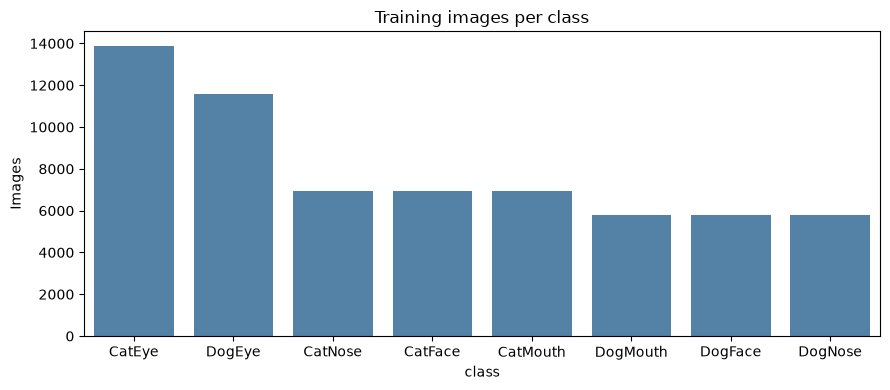

In [3]:
# --- 1.2 Number of images in each class ---
class_counts = train_df["class"].value_counts()
print(class_counts)
print(f"\nLargest / smallest class: {class_counts.max() / class_counts.min():.1f}x")

plt.figure(figsize=(9, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue")
plt.title("Training images per class")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

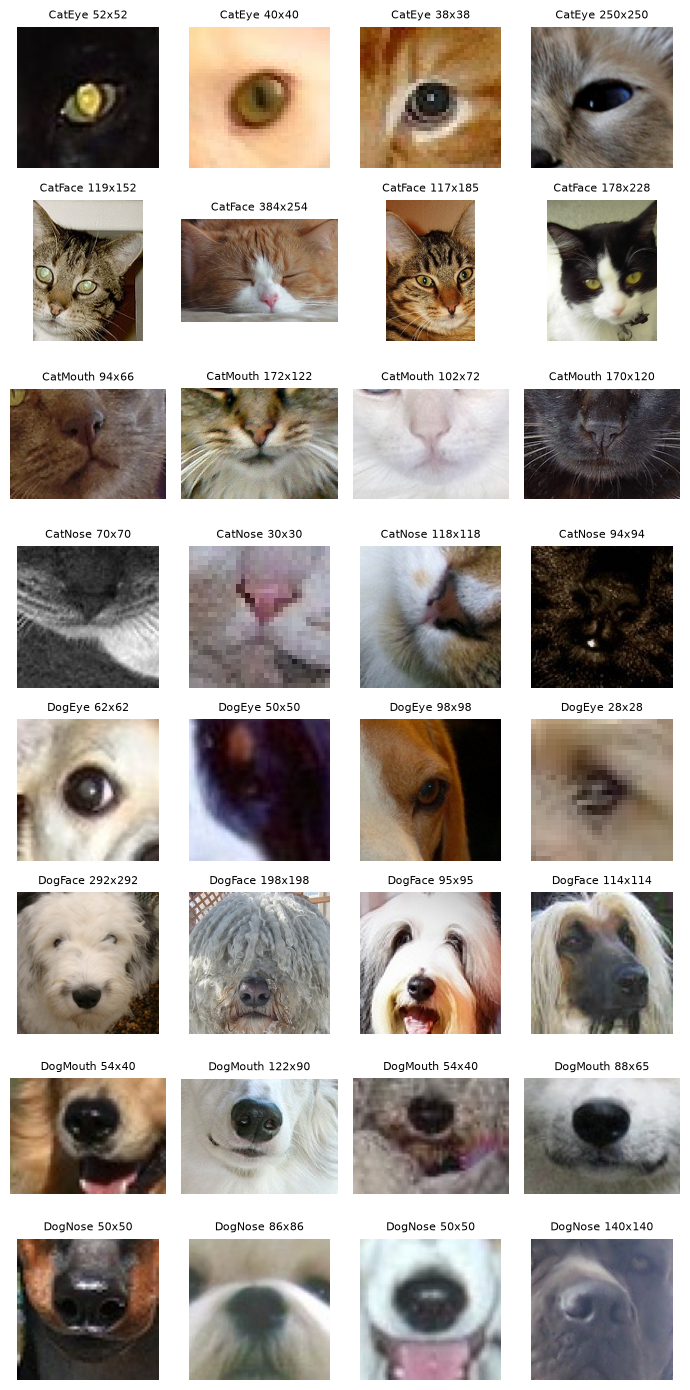

In [4]:
# --- 1.3 Sample images from each class ---
CLASS_NAMES = sorted(train_df["class"].unique())

fig, axes = plt.subplots(len(CLASS_NAMES), 4, figsize=(7, 14))
for row, c in enumerate(CLASS_NAMES):
    samples = train_df[train_df["class"] == c].sample(4, random_state=RANDOM_SEED)
    for col, filename in enumerate(samples["filename"]):
        img = Image.open(os.path.join(TRAIN_IMG_DIR, filename))
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{c} {img.width}x{img.height}", fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [5]:
# --- 1.4 Data quality: image sizes, shapes and broken files (checked on 3,000 random images each) ---
def image_info(folder, filenames):
    rows = []
    for f in filenames:
        try:
            with Image.open(os.path.join(folder, f)) as img:
                img.load()
                rows.append((f, img.width, img.height, True))
        except Exception:
            rows.append((f, None, None, False))
    return pd.DataFrame(rows, columns=["filename", "width", "height", "readable"])

train_info = image_info(TRAIN_IMG_DIR, train_df["filename"].sample(3000, random_state=RANDOM_SEED))
test_info = image_info(TEST_IMG_DIR, pd.Series(os.listdir(TEST_IMG_DIR)).sample(3000, random_state=RANDOM_SEED))
for info in (train_info, test_info):
    info["square"] = info["width"] == info["height"]

print("Broken images:", (~train_info["readable"]).sum() + (~test_info["readable"]).sum())
print(train_info[["width", "height"]].describe().round(0))

train_info = train_info.merge(train_df[["filename", "class"]], on="filename")
print("\n% of square images per class (train):")
print((train_info.groupby("class")["square"].mean() * 100).round(0))
print(f"\nSquare images overall -> train: {train_info['square'].mean():.0%}, test: {test_info['square'].mean():.0%}")

Broken images: 0
        width  height
count  3000.0  3000.0
mean    114.0   110.0
std      90.0    94.0
min      10.0    10.0
25%      54.0    50.0
50%      86.0    80.0
75%     144.0   132.0
max     829.0   958.0

% of square images per class (train):
class
CatEye      100.0
CatFace       1.0
CatMouth      0.0
CatNose      99.0
DogEye      100.0
DogFace      57.0
DogMouth      0.0
DogNose     100.0
Name: square, dtype: float64

Square images overall -> train: 64%, test: 32%


### Inspection findings

| Topic | Finding |
| :--- | :--- |
| Structure | Every training image has a label and there are no missing values. All files are readable JPGs. |
| Class balance | **Imbalanced.** CatEye has 2.4x as many images as DogFace, DogMouth or DogNose, because every animal gives two eye crops. A model that always guessed CatEye would get about 22%, so that is the baseline to beat. The split in Task 2 is stratified to keep these proportions. |
| Image sizes | Very varied: from under 10 px to over 1,000 px wide, with a median of about 80 px. All images need resizing to one size. |
| Image shape | In training, eyes and noses are almost always square and mouths are always wide. In the test set only about a third of images are square, so test crops come in more varied shapes. The model should not learn "square = eye or nose", so training uses random crops with varied shapes (Task 2). |
| Unclear boundaries | Mouth crops often include the nose, and tiny crops are very blurry. Mouth vs Nose and Cat vs Dog for the same part are likely to be the hardest pairs. |

**How the data will be used:** `train_labels.csv` is split 80/20 into training and validation sets. The model learns from the training set only; the validation set is used to monitor training and to measure performance. The test images are only used at the end to create the Kaggle submission file (`image_id,class`) in the order of `sample_submission.csv`.

# Task 2: Data Preprocessing and Pipeline Preparation

In [6]:
# --- 2.1 Label encoding and stratified train/validation split ---
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
train_df["label"] = train_df["class"].map(CLASS_TO_IDX)
print(CLASS_TO_IDX)

train_split, val_split = train_test_split(
    train_df, test_size=0.2, stratify=train_df["label"], random_state=RANDOM_SEED)
print("Train:", len(train_split), "| Validation:", len(val_split))
print(pd.DataFrame({
    "train %": train_split["class"].value_counts(normalize=True) * 100,
    "val %": val_split["class"].value_counts(normalize=True) * 100,
}).round(1))

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Train: 50928 | Validation: 12732
          train %  val %
class                   
CatEye       21.8   21.8
CatFace      10.9   10.9
CatMouth     10.9   10.9
CatNose      10.9   10.9
DogEye       18.2   18.2
DogFace       9.1    9.1
DogMouth      9.1    9.1
DogNose       9.1    9.1


In [7]:
# --- 2.2 Resizing, normalisation and augmentation ---
IMG_SIZE = 128
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet statistics, expected by pretrained ResNet18

# Training images get random augmentation every epoch
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.75, 1.33)),  # random zoom and shape
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),             # pixels 0-255 -> 0-1
    transforms.Normalize(MEAN, STD),
])

# Validation and test images all get the same fixed steps (no randomness)
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [8]:
# --- 2.3 Dataset and DataLoaders ---
class FacialFeatureDataset(Dataset):
    def __init__(self, df, folder, transform):
        self.df = df.reset_index(drop=True)
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.folder, row["filename"])).convert("RGB")
        target = row["label"] if "label" in row else row["image_id"]  # test images have no label
        return self.transform(img), target


# Test images in the same order as sample_submission.csv (its IDs have no leading zeros)
test_df = sample_sub[["image_id"]].copy()
test_df["filename"] = test_df["image_id"].str.zfill(5) + ".jpg"

BATCH_SIZE = 64
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
train_loader = DataLoader(FacialFeatureDataset(train_split, TRAIN_IMG_DIR, train_transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(FacialFeatureDataset(val_split, TRAIN_IMG_DIR, eval_transform),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(FacialFeatureDataset(test_df, TEST_IMG_DIR, eval_transform),
                         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

images, labels = next(iter(train_loader))
print("Batch of images:", tuple(images.shape), "| labels:", labels[:8].tolist())

Batch of images: (64, 3, 128, 128) | labels: [3, 0, 3, 6, 4, 2, 1, 1]


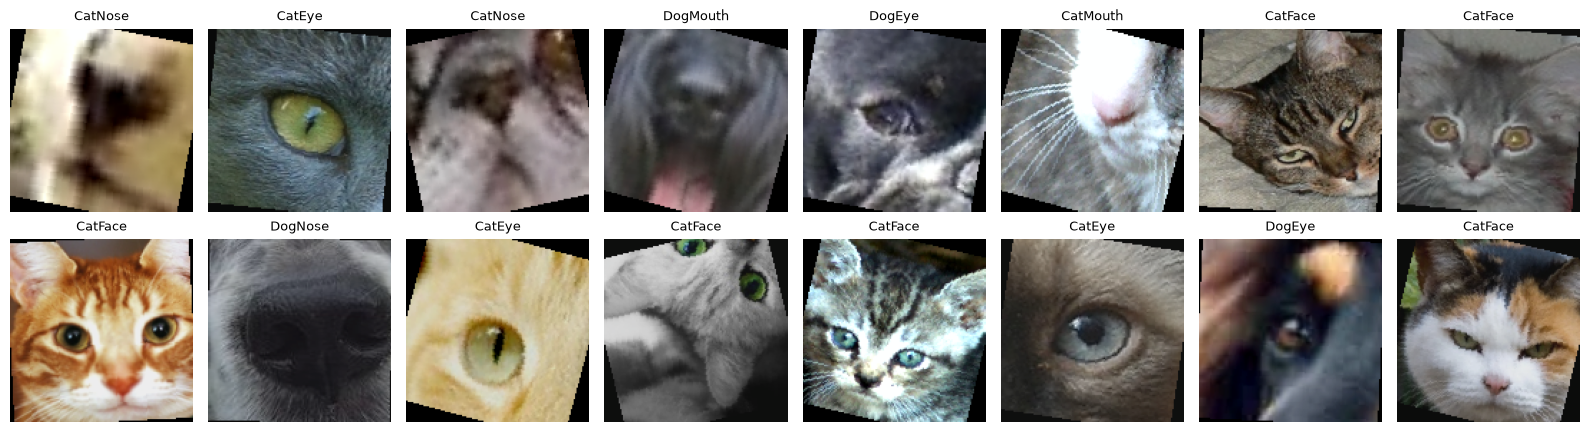

In [9]:
# --- 2.4 Check: one augmented training batch ---
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img, label in zip(axes.flatten(), images, labels):
    img = img.permute(1, 2, 0).numpy() * STD + MEAN  # undo normalisation for display
    ax.imshow(img.clip(0, 1))
    ax.set_title(IDX_TO_CLASS[int(label)], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Preprocessing choices

| Step | Choice | Why |
| :--- | :--- | :--- |
| Resize | 128 x 128 | Images are small (median ~80 px), so 128 keeps the detail while staying fast to train. |
| Normalise | `ToTensor()` (0-1), then ImageNet mean/std | Scaled inputs train faster (lec09); the pretrained ResNet18 expects ImageNet statistics. |
| Labels | Class names mapped to 0-7 | Cross-entropy loss in PyTorch takes integer class labels. |
| Split | Stratified 80/20, `random_state=42` | Keeps the same class proportions in both sets despite the imbalance (as in LAB4). |
| Augmentation | Random crop with varied zoom and shape, flip, rotation ±15°, brightness/contrast | Gives more variety and reduces overfitting (lec11). The varied crop shapes stop the model relying on image shape, which differs in the test set. Training images only. |
| Loaders | `Dataset` + `DataLoader`, batch size 64 | Loads images in mini-batches instead of all at once; training data shuffled, test kept in submission order. |

**Avoiding data leakage:** the split is made before any training, validation and test images use the same fixed `eval_transform` with no augmentation, the normalisation values are fixed constants, and the test images are only used for the final predictions.

# Task 3: Model Selection and Pipeline Development

Two models are built so they can be compared in Task 6:
* **Model A - simple CNN**, trained from scratch, following the "typical CNN" structure from lec11 (convolution -> ReLU -> pooling blocks, then flatten -> fully connected -> softmax).
* **Model B - ResNet18 with transfer learning**: a CNN pretrained on ImageNet, with its last layer replaced by a new 8-class layer and then fine-tuned on this dataset (lec11, transfer learning).

In [ ]:
# --- 3.1 Model A: simple CNN ---
import time
import torch.nn as nn
from torchvision import models

NUM_CLASSES = len(CLASS_NAMES)

def conv_block(c_in, c_out):
    """Convolution -> batch normalisation -> ReLU -> 2x2 max pooling (halves height and width)."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        # 128x128 -> 64 -> 32 -> 16 -> 8, with more filters in each deeper block
        self.features = nn.Sequential(conv_block(3, 32), conv_block(32, 64), conv_block(64, 128), conv_block(128, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),                      # 128 feature maps of 8x8 -> 8,192 values
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.5),                   # randomly drops half the neurons while training (lec11)
            nn.Linear(256, num_classes),       # one output per class
        )

    def forward(self, x):
        return self.classifier(self.features(x))

print(SimpleCNN())
print("Trainable parameters:", sum(p.numel() for p in SimpleCNN().parameters()))

In [ ]:
# --- 3.2 Model B: pretrained ResNet18 (transfer learning) ---
def build_resnet18(num_classes=NUM_CLASSES):
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)  # weights learned on ImageNet
    model.fc = nn.Linear(model.fc.in_features, num_classes)                 # replace 1000-class layer with 8 classes
    return model

print("ResNet18 final layer:", build_resnet18().fc)
print("Trainable parameters:", sum(p.numel() for p in build_resnet18().parameters()))

In [ ]:
# --- 3.3 Training pipeline ---
def run_epoch(model, loader, criterion, optimizer=None):
    """One pass over the data: trains the model if an optimizer is given, otherwise only evaluates it."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)              # forward pass
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()                  # backpropagation
                optimizer.step()                 # update the weights
            total_loss += loss.item() * len(labels)
            correct += (outputs.argmax(1) == labels).sum().item()
            count += len(labels)
    return total_loss / count, correct / count


def train_model(model, name, epochs, lr):
    """Train for a number of epochs, record the learning curves and keep the best model on validation accuracy."""
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_path = os.path.join(WORKING_DIR, f"{name}_best.pt")
    history, best_acc = [], 0.0

    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), best_path)
        print(f"{name} epoch {epoch}/{epochs} | train loss {train_loss:.3f}, acc {train_acc:.3f}"
              f" | val loss {val_loss:.3f}, acc {val_acc:.3f} | {time.time() - start:.0f}s")

    model.load_state_dict(torch.load(best_path))
    print(f"Best validation accuracy for {name}: {best_acc:.4f}")
    return model, pd.DataFrame(history)

In [ ]:
# --- 3.4 Predictions for the Kaggle test set ---
def predict(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for images, _ in loader:
            predictions.extend(model(images.to(DEVICE)).argmax(1).cpu().tolist())
    return predictions

def make_submission(model, filename="submission.csv"):
    submission = pd.DataFrame({
        "image_id": test_df["image_id"],
        "class": [IDX_TO_CLASS[p] for p in predict(model, test_loader)],
    })
    submission.to_csv(os.path.join(WORKING_DIR, filename), index=False)
    return submission

### Model architecture

| | Model A: simple CNN | Model B: ResNet18 |
| :--- | :--- | :--- |
| Input | 128 x 128 x 3 (RGB) | 128 x 128 x 3 (RGB) |
| Main components | 4 blocks of 3x3 convolution -> batch norm -> ReLU -> 2x2 max pooling (32, 64, 128, 128 filters), then flatten -> fully connected (256) -> dropout 0.5 | 18-layer CNN with residual (skip) connections, pretrained on 1.2 million ImageNet images |
| Output layer | Fully connected, 8 outputs | New fully connected layer, 8 outputs |
| Output activation | Softmax (applied inside `CrossEntropyLoss`; the highest score is the predicted class) | Softmax (same) |
| Why | A from-scratch baseline that shows what a basic CNN can learn on its own | Pretrained filters already detect edges, textures and shapes, so it needs less data and training to reach high accuracy |

### Training settings

| Setting | Model A | Model B | Why |
| :--- | :--- | :--- | :--- |
| Loss | Cross-entropy | Cross-entropy | Standard loss for multi-class classification (lec09/11). |
| Optimiser | Adam | Adam | Adapts the step size for each weight, so it works well without much tuning. |
| Learning rate | 0.001 | 0.0001 | Model A starts from random weights. Model B uses a smaller rate so it does not overwrite the useful pretrained weights. |
| Batch size | 64 | 64 | Fits comfortably in GPU memory and gives stable updates. |
| Epochs | 10 | 10 | Enough to see the learning curves level off; the best epoch on validation accuracy is kept. |

# Task 4: Training Strategy and Overfitting/Underfitting Management

In [ ]:
# --- 4.1 Train Model A: simple CNN ---
seed_everything()
cnn_model, cnn_history = train_model(SimpleCNN(), "simple_cnn", epochs=10, lr=1e-3)

In [ ]:
# --- 4.2 Train Model B: ResNet18 ---
seed_everything()
resnet_model, resnet_history = train_model(build_resnet18(), "resnet18", epochs=10, lr=1e-4)

In [ ]:
# --- 4.3 Learning curves ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, history in [("Simple CNN", cnn_history), ("ResNet18", resnet_history)]:
    axes[0].plot(history["epoch"], history["train_loss"], "--", label=f"{name} train")
    axes[0].plot(history["epoch"], history["val_loss"], label=f"{name} validation")
    axes[1].plot(history["epoch"], history["train_acc"], "--", label=f"{name} train")
    axes[1].plot(history["epoch"], history["val_acc"], label=f"{name} validation")
axes[0].set_title("Loss")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

# Task 5 & 6: Evaluation, Confusion Matrix, and Kaggle Submission

**What to write:**
* Evaluate validation accuracy, precision, recall, F1-score, and confusion matrix.
* Analyze misclassifications and suggest future architectural or pipeline improvements.

In [ ]:
# --- 5.1 First Kaggle submission (best model so far, by validation accuracy) ---
if resnet_history["val_acc"].max() >= cnn_history["val_acc"].max():
    best_name, best_model = "ResNet18", resnet_model
else:
    best_name, best_model = "Simple CNN", cnn_model

submission = make_submission(best_model)
print("Submission made with:", best_name)
print(submission.head())
print(submission["class"].value_counts())